**GATY'S OPTIMIZATION**

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
content = Path('landscape.jpg')
style = Path('style.jpg')

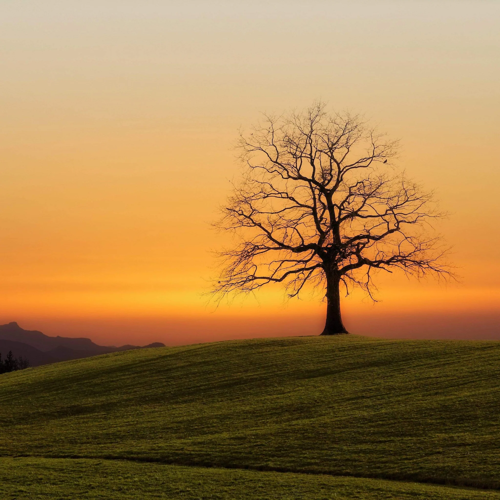

In [3]:
with Image.open(content) as img:
  display(img.resize((500,500)))

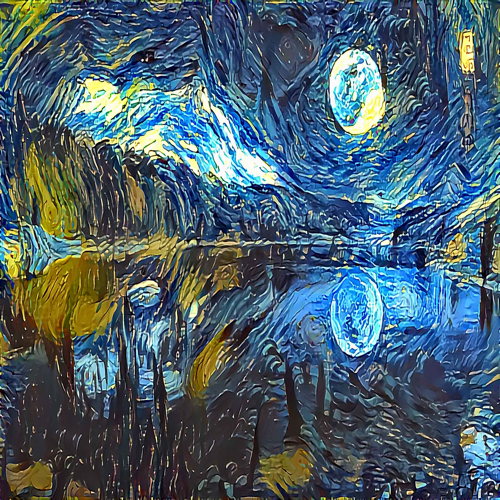

In [4]:
with Image.open(style) as img:
  display(img.resize((500,500)))

In [ ]:
model = torchvision.models.vgg19(weights = torchvision.models.VGG19_Weights.DEFAULT).to(device)
print(model)

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:04<00:00, 143MB/s]


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [ ]:
for params in model.features.parameters():
  params.requires_grad_(False)

# Simply setting the model to evaluation model will still track and store gradients but not update(slowing down training)

In [ ]:
print('Total Parameters ',sum([p.numel() for p in model.parameters()]))

Total Parameters  143667240


In [ ]:
# Data Preprocessing
with Image.open(content) as img:
  data = np.array(img.resize((512,512)))
  data = torch.from_numpy(data)
  data = data.permute(2,0,1)/255
  data = (data - torch.tensor([0.485, 0.456, 0.406]).view(3,1,1))/torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
  data = data.unsqueeze(0).to(device) # Adding batch dimension at axis 0
  print('Content ',data.shape)

with Image.open(style) as img:
  style_data = np.array(img.resize((512,512)))
  style_data = torch.from_numpy(style_data)
  style_data = style_data.permute(2,0,1)/255.0
  style_data = (style_data - torch.tensor([0.485, 0.456, 0.406]).view(3,1,1))/torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
  style_data = style_data.unsqueeze(0).to(device)
  print('Style ',style_data.shape)

print('Content image gradient tracking ',data.requires_grad)
print('Style image gradient tracking ',style_data.requires_grad)

Content  torch.Size([1, 3, 512, 512])
Style  torch.Size([1, 3, 512, 512])
Content image gradient tracking  False
Style image gradient tracking  False


In [ ]:
def extraction(dat,indices=[]):

  s = []

  for count,layer in enumerate(model.features):
    dat = layer(dat)
    if count in indices:
      s.append(dat)
      if max(indices) == count:
        return s

In [ ]:
feature_content = extraction(data,[21])
print(feature_content[0].shape)
style_features = extraction(style_data,[0,5,10,19,28])
print(len(style_features))

torch.Size([1, 512, 64, 64])
5


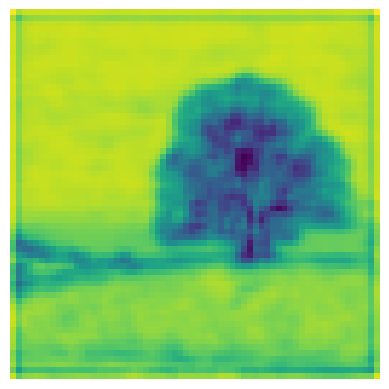

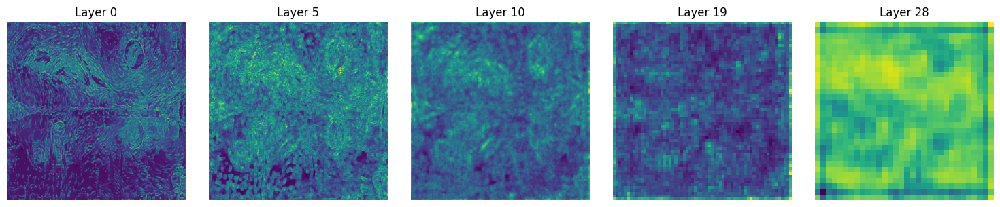

In [ ]:
heatmap = feature_content[0].squeeze(0).mean(dim=0).detach().cpu()

plt.imshow(heatmap, cmap='viridis')
plt.axis('off')

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i in range(5):

    heatmap = style_features[i].squeeze(0).mean(dim = 0).detach().cpu()

    axes[i].imshow(heatmap, cmap='viridis')
    axes[i].axis('off')
    axes[i].set_title(f"Layer {[0,5,10,19,28][i]}")

plt.tight_layout()

In [ ]:
def gram_matrix(image):
  c,h,w = image[0].shape
  image = image.squeeze(0).view(c,-1) # shape: (c,h*w)
  gram_matrix = torch.matmul(image,image.T).to(device) # shape : (c,c) pairwise inner products of different channels(features)
  return gram_matrix

In [ ]:
style_gram = [gram_matrix(i) for i in style_features]
#target = data.clone().requires_grad_(True)

target = torch.rand(1, 3, 512, 512, device=device).requires_grad_(True)


AssertionError: Torch not compiled with CUDA enabled

In [ ]:
optimizer = torch.optim.Adam([target],lr=0.075)
loss = torch.nn.functional.mse_loss

In [ ]:
def training(epochs,content_weight,style_weight):
  style_checkpoints = [0,5,10,19,28]
  content_checkpoint = [21]
  content_history = []
  style_history = []
  total_history = []

  for i in range(epochs):

    target_style = []
    content_features = None
    style_loss = 0


    optimizer.zero_grad()
    x = target # pointer x points towards memory(target)

# we want target to change only by gradient descent(not by convolutions)-> x occupies separate memory but gradients still flow to target,if we don't use x , target will change by forward pass(without gradient descent) only and will feed that distorted target back in 2nd epoch

    for count,layer in enumerate(model.features):

      x = layer(x) # pointer x points towards a new memory block(having layer(x)) hence target don't get changed

      if count in content_checkpoint:
        content_features = x
      if count in style_checkpoints:
        target_style.append(x)
      if count>28:
        break

    content_loss = loss(feature_content[0],content_features)

    live_gram = [gram_matrix(i) for i in target_style]

    for j in range(len(style_gram)):
      style_loss += loss(style_gram[j],live_gram[j])

    total_loss = content_weight * content_loss + style_weight * style_loss

    content_history.append(content_loss.item())
    style_history.append(style_loss.item()*1e-8)
    total_history.append(total_loss.item()*1e-2)
    if (i + 1)%100 == 0:
      print(f'Epoch : {i+1} Style Loss : {style_loss.item()} Content Loss : {content_loss.item()} Total Loss : {total_loss.item()}')
    total_loss.backward()
    optimizer.step()

  return target,content_history,style_history,total_history

In [ ]:
target,content_history,style_history,total_history = training(epochs=700,content_weight=200,style_weight = 1e-8)

Epoch : 100 Style Loss : 9600913408.0 Content Loss : 67.98533630371094 Total Loss : 13693.076171875
Epoch : 200 Style Loss : 4867406848.0 Content Loss : 67.8250503540039 Total Loss : 13613.68359375
Epoch : 300 Style Loss : 3790121472.0 Content Loss : 67.77432250976562 Total Loss : 13592.765625
Epoch : 400 Style Loss : 3282921216.0 Content Loss : 67.7490234375 Total Loss : 13582.6337890625
Epoch : 500 Style Loss : 2969623040.0 Content Loss : 67.73406982421875 Total Loss : 13576.5107421875
Epoch : 600 Style Loss : 2771316480.0 Content Loss : 67.72163391113281 Total Loss : 13572.0400390625
Epoch : 700 Style Loss : 2624260096.0 Content Loss : 67.71310424804688 Total Loss : 13568.86328125


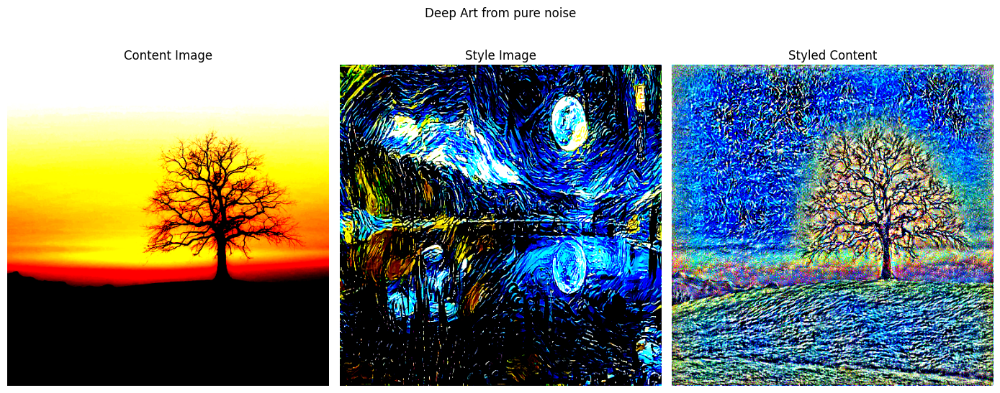

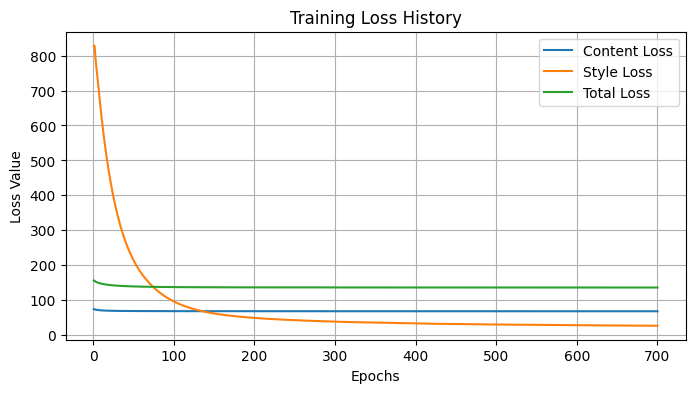

In [ ]:
def show_image(tar):
    tar = tar.squeeze(0)
    tar = torch.clamp(tar, 0, 1) # Keeps pixels safely in visible range
    fig,axes = plt.subplots(1,3,figsize=(14,6))
    axes[0].imshow(torch.clamp(data,0,1).squeeze(0).permute(1,2,0).detach().cpu().numpy())
    axes[0].axis('off')
    axes[0].set_title('Content Image')
    axes[1].imshow(torch.clamp(style_data,0,1).squeeze(0).permute(1,2,0).detach().cpu().numpy())
    axes[1].axis('off')
    axes[1].set_title('Style Image')
    axes[2].imshow(tar.detach().cpu().permute(1, 2, 0).numpy())
    axes[2].axis('off')
    axes[2].set_title('Styled Content')
    plt.suptitle("Deep Art from pure noise")
    plt.tight_layout()
    plt.show()

def show_losses(conte, styl, total):
    plt.figure(figsize=(8, 4))
    plt.plot([i for i in range(1,701)],conte, label="Content Loss")
    plt.plot([i for i in range(1,701)],styl, label="Style Loss")
    plt.plot([i for i in range(1,701)],total, label="Total Loss")
    plt.legend()
    plt.xlabel("Epochs")
    plt.ylabel("Loss Value")
    plt.grid()
    plt.title("Training Loss History")
    plt.show()

show_image(target)
show_losses(content_history, style_history, total_history)

**Fast Inference Approach using AdaIN Style Transfer**

In [2]:
import torch.nn as nn
import torch,torchvision

!wget -O /content/vgg_normalised.pth \
"https://github.com/naoto0804/pytorch-AdaIN/releases/download/v0.0.0/vgg_normalised.pth"

!wget -O /content/decoder.pth \
"https://github.com/naoto0804/pytorch-AdaIN/releases/download/v0.0.0/decoder.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

--2026-10-25 11:01:01--  https://github.com/naoto0804/pytorch-AdaIN/releases/download/v0.0.0/vgg_normalised.pth
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/112338125/d6ae2603-8f3e-4c58-98af-1a248448781e?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-25T12%3A00%3A18Z&rscd=attachment%3B+filename%3Dvgg_normalised.pth&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-25T11%3A00%3A01Z&ske=2026-10-25T12%3A00%3A18Z&sks=b&skv=2018-11-09&sig=LP6iZtjC52QOpXrG9mEJtbyyr4DF9ZjI5kKN4eIOLQs%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MjkyNzg2MSwibmJmIjoxNzkyOTI2MDYxLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVj

In [3]:
vgg_weights = torch.load(
    "/content/vgg_normalised.pth",
    map_location="cpu"
)

decoder_weights = torch.load(
    "/content/decoder.pth",
    map_location="cpu"
)

print("\nVGG keys:")
print(vgg_weights.keys())

print("\nDecoder keys:")
print(decoder_weights.keys())

print("\nEncoder Model keys:")
print(encoder.state_dict().keys())
print("\nDecoder Model keys:")
print(decoder.state_dict().keys())



VGG keys:
odict_keys(['0.weight', '0.bias', '2.weight', '2.bias', '5.weight', '5.bias', '9.weight', '9.bias', '12.weight', '12.bias', '16.weight', '16.bias', '19.weight', '19.bias', '22.weight', '22.bias', '25.weight', '25.bias', '29.weight', '29.bias', '32.weight', '32.bias', '35.weight', '35.bias', '38.weight', '38.bias', '42.weight', '42.bias', '45.weight', '45.bias', '48.weight', '48.bias', '51.weight', '51.bias'])

Decoder keys:
odict_keys(['1.weight', '1.bias', '5.weight', '5.bias', '8.weight', '8.bias', '11.weight', '11.bias', '14.weight', '14.bias', '18.weight', '18.bias', '21.weight', '21.bias', '25.weight', '25.bias', '28.weight', '28.bias'])

Encoder Model keys:


NameError: name 'encoder' is not defined

In [4]:
print('Imagnet means used to shift caffe vgg19 image channels',vgg_weights['0.bias']) # Imagenet Means
print('Permutation matrix to convert RGB to BGR \n',vgg_weights['0.weight']) # Permutation matrix to convert RGB to BGR

Imagnet means used to shift caffe vgg19 image channels tensor([-103.9390, -116.7790, -123.6800])
Permutation matrix to convert RGB to BGR 
 tensor([[[[  0.]],

         [[  0.]],

         [[255.]]],


        [[[  0.]],

         [[255.]],

         [[  0.]]],


        [[[255.]],

         [[  0.]],

         [[  0.]]]])


In [11]:
# Loading images normalized to 0-1 required for pretrained VGG19 and Decoder (github.com/naoto0804/pytorch-AdaIN)
from PIL import Image
from pathlib import Path
import numpy as np

content = Path('landscape.jpg')
style = Path('style.jpg')

def load_and_preprocess(img,category,style_size = 512):
  if category == 'content':
    with Image.open(img) as img:
      data = torchvision.transforms.ToTensor()(img)
      data = torchvision.transforms.Resize(512)(data)
      #data = data[[2,1,0],:,:] # RGB to BGR conversion done in standard preprocessing in official paper
      #data = data - torch.tensor([103.939, 116.779, 123.68]).view(3,1,1)
      data = data.unsqueeze(0).to(device) # Adding batch dimension at axis 0
      print('Content ',data.shape)
      return data
  else:
    with Image.open(img) as img:
      style_data = torchvision.transforms.ToTensor()(img)
      style_data = torchvision.transforms.Resize(style_size)(style_data) # Resize only the smaller edge not both edge (preserving aspect ratio)
    #style_data = style_data[[2,1,0],:,:]
    #style_data = style_data - torch.tensor([103.939, 116.779, 123.68]).view(3,1,1) # standard preprocessing using means from Imagenet Dataset
      style_data = style_data.unsqueeze(0).to(device)
      print('Style ',style_data.shape)
      return style_data

data = load_and_preprocess(content,'content')
style_data = load_and_preprocess(style,'style')

print('Content image gradient tracking ',data.requires_grad)
print('Style image gradient tracking ',style_data.requires_grad)

Content  torch.Size([1, 3, 512, 512])
Style  torch.Size([1, 3, 512, 819])
Content image gradient tracking  False
Style image gradient tracking  False


In [6]:
class Encoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.model = nn.Sequential(
        nn.Conv2d(3,3,(1,1),stride = 1,padding = 0), # this subtracts [103.939, 116.779, 123.68] from each channel (BGR)
        nn.ReflectionPad2d(1),
        nn.Conv2d(3,64,(3,3),stride=1,padding=0),
        nn.ReLU(), # 1_1
        nn.ReflectionPad2d(1),
        nn.Conv2d(64,64,(3,3),stride=1,padding=0),
        nn.ReLU(), # 1_2
        nn.MaxPool2d(2,stride=2,ceil_mode = True),
        nn.ReflectionPad2d(1),
        nn.Conv2d(64,128,kernel_size = (3,3),stride = 1,padding = 0),
        nn.ReLU(), # 2_1
        nn.ReflectionPad2d(1),
        nn.Conv2d(128,128,kernel_size = (3,3),stride = 1,padding = 0),
        nn.ReLU(), # 2_2
        nn.MaxPool2d(2,stride = 2,ceil_mode = True),
        nn.ReflectionPad2d(1),
        nn.Conv2d(128,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(), # 3_1
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(), # 3_2
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(), # 3_3
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(), # 3_4
        nn.MaxPool2d(2,stride = 2,ceil_mode = True),
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,512,(3,3),stride = 1,padding = 0),
        nn.ReLU() # 4_1
    )
  def forward(self,x):
    return self.model(x)

encoder = Encoder()

print(encoder)

#print("Output Shape ",encoder(torch.rand((3,512,512))).shape)

encoder.load_state_dict({
    "model.0.weight":  vgg_weights["0.weight"],
    "model.0.bias":    vgg_weights["0.bias"],

    "model.2.weight":  vgg_weights["2.weight"],
    "model.2.bias":    vgg_weights["2.bias"],

    "model.5.weight":  vgg_weights["5.weight"],
    "model.5.bias":    vgg_weights["5.bias"],

    "model.9.weight":  vgg_weights["9.weight"],
    "model.9.bias":    vgg_weights["9.bias"],

    "model.12.weight":  vgg_weights["12.weight"],
    "model.12.bias":    vgg_weights["12.bias"],

    "model.16.weight": vgg_weights["16.weight"],
    "model.16.bias":   vgg_weights["16.bias"],

    "model.19.weight": vgg_weights["19.weight"],
    "model.19.bias":   vgg_weights["19.bias"],

    "model.22.weight": vgg_weights["22.weight"],
    "model.22.bias":   vgg_weights["22.bias"],

    "model.25.weight": vgg_weights["25.weight"],
    "model.25.bias":   vgg_weights["25.bias"],

    "model.29.weight": vgg_weights["29.weight"],
    "model.29.bias":   vgg_weights["29.bias"],
})  # Downloaded vgg19 weights are for full model but we use only upto relu4_1 hence need explicit mapping

encoder.to(device).eval()

Encoder(
  (model): Sequential(
    (0): Conv2d(3, 3, kernel_size=(1, 1), stride=(1, 1))
    (1): ReflectionPad2d((1, 1, 1, 1))
    (2): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): ReflectionPad2d((1, 1, 1, 1))
    (5): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (8): ReflectionPad2d((1, 1, 1, 1))
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (10): ReLU()
    (11): ReflectionPad2d((1, 1, 1, 1))
    (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (15): ReflectionPad2d((1, 1, 1, 1))
    (16): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (17): ReLU()
    (18): ReflectionPad2d((1, 1, 1, 1))
    (19): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (20): ReLU()
    (21): ReflectionPad2d((1, 1, 1, 1))
    

Encoder(
  (model): Sequential(
    (0): Conv2d(3, 3, kernel_size=(1, 1), stride=(1, 1))
    (1): ReflectionPad2d((1, 1, 1, 1))
    (2): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): ReflectionPad2d((1, 1, 1, 1))
    (5): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (8): ReflectionPad2d((1, 1, 1, 1))
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (10): ReLU()
    (11): ReflectionPad2d((1, 1, 1, 1))
    (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (15): ReflectionPad2d((1, 1, 1, 1))
    (16): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (17): ReLU()
    (18): ReflectionPad2d((1, 1, 1, 1))
    (19): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (20): ReLU()
    (21): ReflectionPad2d((1, 1, 1, 1))
    

In [12]:
# Extracting embeddings for content and style from layer 31
def extraction(content,style):

  return encoder(content),encoder(style)

features,style1 = extraction(data,style_data)
print(features.shape)

torch.Size([1, 512, 64, 64])


Text(0.5, 1.0, 'Feature map of style at layer relu4_1')

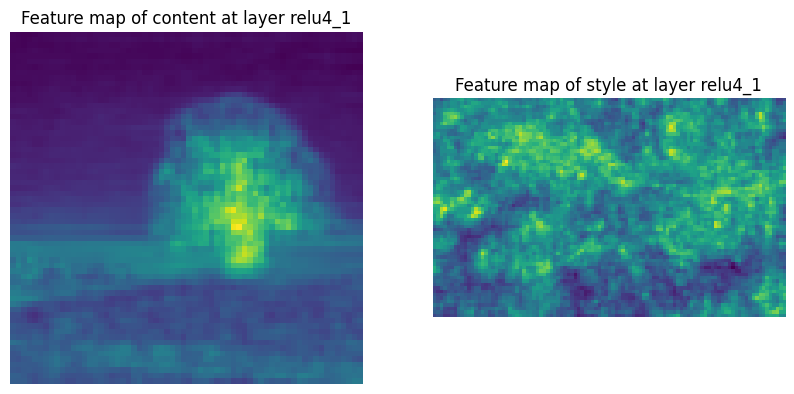

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10,8))
plt.subplot(1,2,1)
plt.imshow(features.squeeze(0).sum(axis=0).detach().numpy())
plt.axis('off')
plt.title('Feature map of content at layer relu4_1')
plt.subplot(1,2,2)
plt.imshow(style1.squeeze(0).sum(axis=0).detach().numpy())
plt.axis('off')
plt.title("Feature map of style at layer relu4_1")

In [8]:
def adain(content,style,alpha):
  eps = 1e-5

  content1 = content.view(content.size(0),content.size(1),-1) # Shape: (1,512,4096) Flattening height and width
  style1 = style.view(style.size(0),style.size(1),-1)

  mu_content = content1.mean(axis = 2).unsqueeze(2) # Shape : (1,512,1)
  mu_style = style1.mean(axis = 2).unsqueeze(2)
  # To subtract a tensor (1,512) from (1,512,1024) , we need to reshape : (1,512) -> (1,512,1)
  std_content = torch.sqrt(((content1 - mu_content)**2).mean(axis = 2) + eps).unsqueeze(2) # Shape : (1,512,1)
  std_style = torch.sqrt(((style1 - mu_style)**2).mean(axis = 2) + eps).unsqueeze(2) # Shape : (1,512,1)

  transformed_content = ((content1 - mu_content)/std_content)*std_style + mu_style # Shape:(1,512,4096)

  final =  alpha * transformed_content.view(content.size(0),content.size(1),content.size(2),-1) + (1-alpha) * content # Shape:(1,512,64,64)

  #print('Content ',content.shape)
  #print('Mean of content ',mu_content.shape)
  #print('Std of content ',std_content.shape)
  #print('Transformed Content ',transformed_content.shape)
  #print('final Content ',final.shape)

  return final

Text(0.5, 0.98, 'Style Transfer using Adaptive Instance Normalization(Adain)')

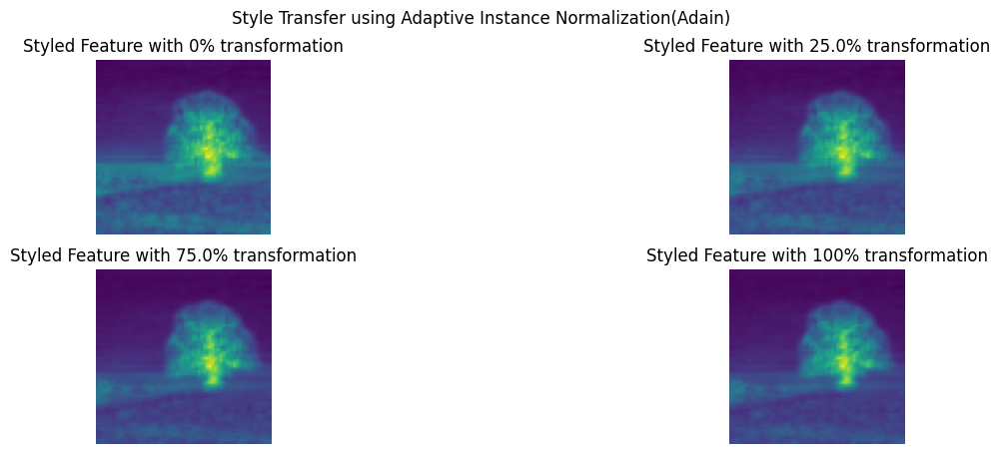

In [ ]:
alpha = [0,0.25,0.75,1]



fig,axes = plt.subplots(2,2,figsize = (15,5))
for i in range(len(alpha)):
  output = adain(features,style1,alpha[i])
  axes[i//2,i%2].imshow(output.squeeze(0).sum(axis = 0).detach().numpy())
  axes[i//2,i%2].set_title(f"Styled Feature with {alpha[i]*100}% transformation")
  axes[i//2,i%2].axis("off")
plt.suptitle('Style Transfer using Adaptive Instance Normalization(Adain)')

In [9]:
class Decoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.model = nn.Sequential(
        nn.ReflectionPad2d(1),
        nn.Conv2d(512,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.Upsample(scale_factor=2,mode="nearest"),
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,256,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.ReflectionPad2d(1),
        nn.Conv2d(256,128,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.Upsample(scale_factor=2,mode="nearest"),
        nn.ReflectionPad2d(1),
        nn.Conv2d(128,128,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.ReflectionPad2d(1),
        nn.Conv2d(128,64,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.Upsample(scale_factor=2,mode="nearest"),
        nn.ReflectionPad2d(1),
        nn.Conv2d(64,64,(3,3),stride = 1,padding = 0),
        nn.ReLU(),
        nn.ReflectionPad2d(1),
        nn.Conv2d(64,3,(3,3),stride = 1,padding = 0),
    )
  def forward(self,x):
    return self.model(x)

decoder = Decoder()
print(decoder)
# print(decoder(torch.rand(1,512,64,64)).shape)
decoder.model.load_state_dict(torch.load('decoder.pth',map_location=device))
decoder.to(device).eval()

Decoder(
  (model): Sequential(
    (0): ReflectionPad2d((1, 1, 1, 1))
    (1): Conv2d(512, 256, kernel_size=(3, 3), stride=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): ReflectionPad2d((1, 1, 1, 1))
    (5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (6): ReLU()
    (7): ReflectionPad2d((1, 1, 1, 1))
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (9): ReLU()
    (10): ReflectionPad2d((1, 1, 1, 1))
    (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (12): ReLU()
    (13): ReflectionPad2d((1, 1, 1, 1))
    (14): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1))
    (15): ReLU()
    (16): Upsample(scale_factor=2.0, mode='nearest')
    (17): ReflectionPad2d((1, 1, 1, 1))
    (18): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (19): ReLU()
    (20): ReflectionPad2d((1, 1, 1, 1))
    (21): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1))
    (22): ReLU()
    (23): Upsample(scale_factor=2.0, mod

Decoder(
  (model): Sequential(
    (0): ReflectionPad2d((1, 1, 1, 1))
    (1): Conv2d(512, 256, kernel_size=(3, 3), stride=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): ReflectionPad2d((1, 1, 1, 1))
    (5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (6): ReLU()
    (7): ReflectionPad2d((1, 1, 1, 1))
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (9): ReLU()
    (10): ReflectionPad2d((1, 1, 1, 1))
    (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (12): ReLU()
    (13): ReflectionPad2d((1, 1, 1, 1))
    (14): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1))
    (15): ReLU()
    (16): Upsample(scale_factor=2.0, mode='nearest')
    (17): ReflectionPad2d((1, 1, 1, 1))
    (18): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (19): ReLU()
    (20): ReflectionPad2d((1, 1, 1, 1))
    (21): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1))
    (22): ReLU()
    (23): Upsample(scale_factor=2.0, mod

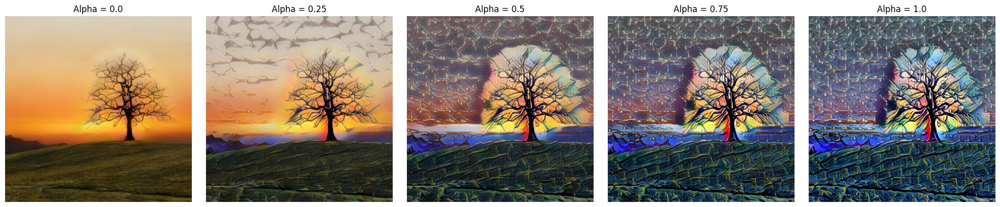

In [ ]:
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(1, len(alphas), figsize=(20, 4))

with torch.no_grad():
  for i, a in enumerate(alphas):
    # 1. Compute AdaIN feature at interpolation alpha
    feat_trans = adain(features, style1, a)

    # 2. Decode back into RGB pixel space
    decoded_img = decoder(feat_trans)
    decoded_img = torch.clamp(decoded_img, 0.0, 1.0).squeeze(0).permute(1, 2, 0)

    # 3. Plot the decoded RGB image
    axes[i].imshow(decoded_img.cpu().numpy())
    axes[i].set_title(f"Alpha = {a}")
    axes[i].axis("off")

plt.tight_layout()

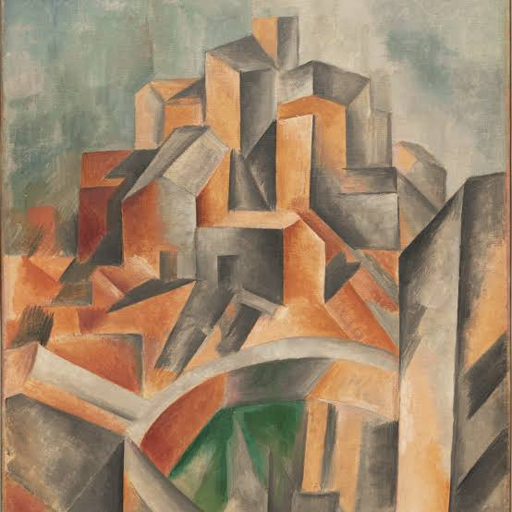

In [ ]:
with Image.open(Path('style2.jfif')) as img:
  img = img.resize((512,512))
  display(img)

Style  torch.Size([1, 3, 512, 512])


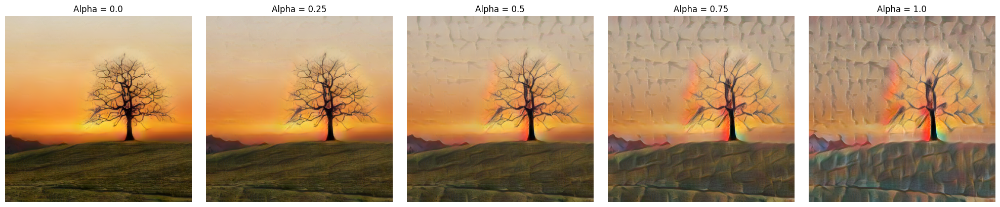

In [ ]:
style_img2 = load_and_preprocess(Path('style2.jfif'),'style')
style_img2_feat = encoder(style_img2)

alphas = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(1, len(alphas), figsize=(20, 4))

with torch.no_grad():
  for i, a in enumerate(alphas):
    # 1. Compute AdaIN feature at interpolation alpha
    feat_trans = adain(features, style_img2_feat, a)

    # 2. Decode back into RGB pixel space
    decoded_img = decoder(feat_trans)
    decoded_img = torch.clamp(decoded_img, 0.0, 1.0).squeeze(0).permute(1, 2, 0)

    # 3. Plot the decoded RGB image
    axes[i].imshow(decoded_img.cpu().numpy())
    axes[i].set_title(f"Alpha = {a}")
    axes[i].axis("off")

plt.tight_layout()

**Style Interpolation (Mixing two styles)**

Content  torch.Size([1, 3, 917, 512])
Style  torch.Size([1, 3, 512, 762])
Style  torch.Size([1, 3, 512, 630])


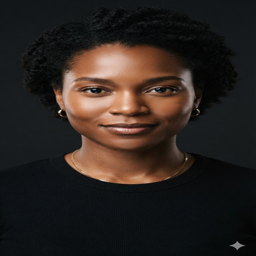

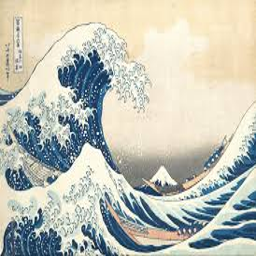

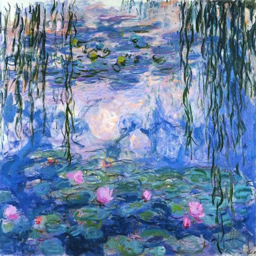

(np.float64(-0.5), np.float64(511.5), np.float64(919.5), np.float64(-0.5))

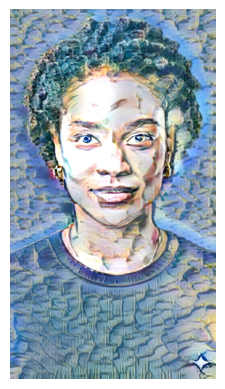

In [13]:
weights = [0.4,0.6]
features = encoder(load_and_preprocess(Path('human_face.jfif'),'content'))
style1 = encoder(load_and_preprocess(Path('style1_new.jfif'),'style'))
style2 = encoder(load_and_preprocess(Path('style2_new.jpg'),'style'))
final_img = weights[0] * adain(features,style1,alpha = 1.0) + weights[1] * adain(features,style2,alpha = 1.0)

with torch.no_grad():
  blended = torch.clamp(decoder(final_img), 0.0, 1.0).squeeze(0).permute(1, 2, 0)

with Image.open(Path('human_face.jfif')) as img:
  display(img.resize((256,256)))
with Image.open(Path('style1_new.jfif')) as img:
  display(img.resize((256,256)))
with Image.open(Path('style2_new.jpg')) as img:
  display(img.resize((256,256)))


plt.imshow(blended.cpu().numpy())
plt.axis('off')

Content  torch.Size([1, 3, 512, 768])
Style  torch.Size([1, 3, 539, 512])
Style  torch.Size([1, 3, 512, 803])


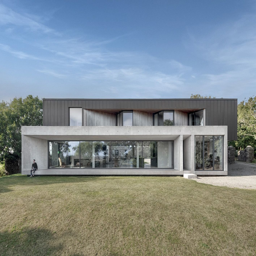

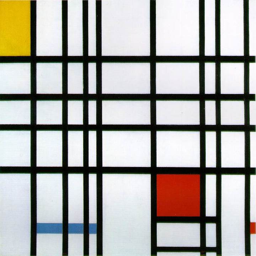

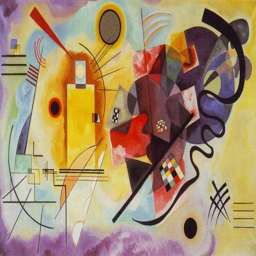

(np.float64(-0.5), np.float64(767.5), np.float64(511.5), np.float64(-0.5))

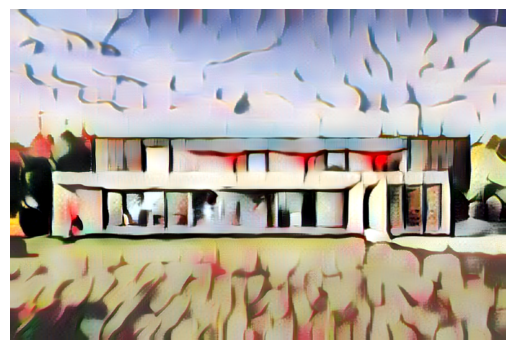

In [14]:
weights = [0.4,0.6]
features = encoder(load_and_preprocess(Path('building.jpg'),'content'))
style1 = encoder(load_and_preprocess(Path('style1_build.jpg'),'style'))
style2 = encoder(load_and_preprocess(Path('style2_build.jfif'),'style'))
final_img = weights[0] * adain(features,style1,alpha = 1.0) + weights[1] * adain(features,style2,alpha = 1.0)

with torch.no_grad():
  blended = torch.clamp(decoder(final_img), 0.0, 1.0).squeeze(0).permute(1, 2, 0)

with Image.open(Path('building.jpg')) as img:
  display(img.resize((256,256)))
with Image.open(Path('style1_build.jpg')) as img:
  display(img.resize((256,256)))
with Image.open(Path('style2_build.jfif')) as img:
  display(img.resize((256,256)))


plt.imshow(blended.cpu().numpy())
plt.axis('off')

**Controlling size of Brush-Strokes by varying size of Style Image**

Content  torch.Size([1, 3, 512, 768])
Style  torch.Size([1, 3, 128, 200])
Style  torch.Size([1, 3, 512, 803])
Style  torch.Size([1, 3, 1280, 2009])


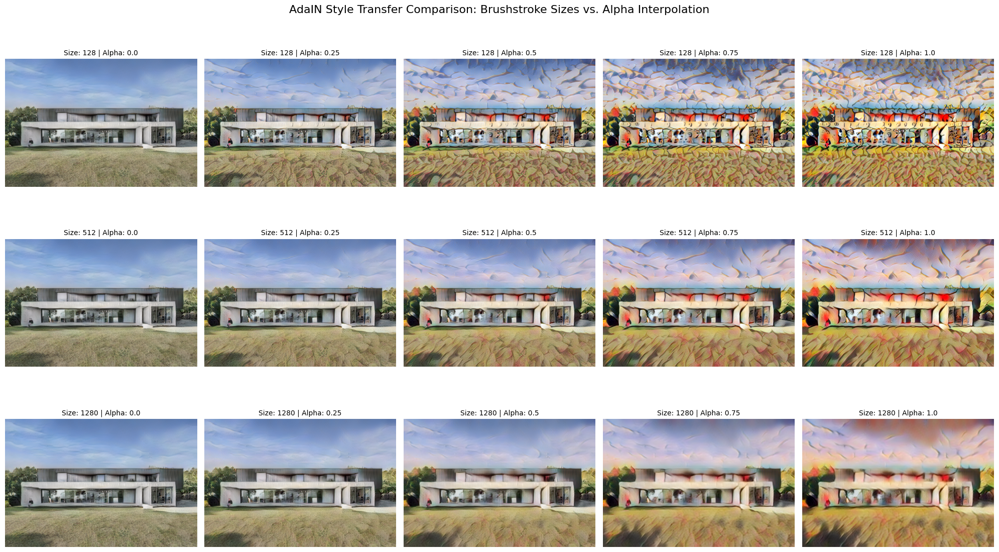

In [18]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# Configure sizes and alphas
sizes = [128, 512, 1280]
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]

content, style = Path('building.jpg'), Path('style2_build.jfif')
data = load_and_preprocess(content, 'content')

# Set up a grid of subplots (rows for sizes, columns for alphas)
fig, axes = plt.subplots(len(sizes), len(alphas), figsize=(20, 12))

with torch.no_grad():
    for row_idx, size in enumerate(sizes):
        # Load the style image at the specific size
        style_resized = load_and_preprocess(style, 'style', style_size=size)
        feat_c, feat_s = extraction(data, style_resized)

        for col_idx, a in enumerate(alphas):
            # Compute AdaIN feature transformation
            feat_trans = adain(feat_c, feat_s, a)

            # Decode back to RGB pixel space
            decoded_img = decoder(feat_trans)
            decoded_img = torch.clamp(decoded_img, 0.0, 1.0).squeeze(0).permute(1, 2, 0)

            # Plot in the grid
            ax = axes[row_idx, col_idx]
            ax.imshow(decoded_img.cpu().numpy())
            ax.axis('off')
            ax.set_title(f"Size: {size} | Alpha: {a}", fontsize=10)

plt.suptitle('AdaIN Style Transfer Comparison: Brushstroke Sizes vs. Alpha Interpolation', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

# Clear GPU cache if available
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [16]:
# Verify if different style sizes produce identical outputs
outputs_dict = {}

with torch.no_grad():
    for size in [256, 512, 1024]:
        # Process style at current size
        style_t = load_and_preprocess(style, 'style', style_size=size)
        feat_c, feat_s = extraction(data, style_t)

        # Compute AdaIN at Alpha = 1.0
        feat_trans = adain(feat_c, feat_s, 1.0)
        decoded_img = decoder(feat_trans)

        # Store the raw tensor to compare them
        outputs_dict[size] = decoded_img.clone().cpu()

# Calculate structural difference (Mean Squared Error) between the generated images
for size_a, img_a in outputs_dict.items():
    for size_b, img_b in outputs_dict.items():
        if size_a < size_b:
            # Interpolate to compare matching spatial dimensions if needed
            diff = torch.nn.functional.mse_loss(img_a, img_b).item()
            print(f"MSE between output of size {size_a} and {size_b}: {diff:.6f}")

Style  torch.Size([1, 3, 256, 401])
Style  torch.Size([1, 3, 512, 803])
Style  torch.Size([1, 3, 1024, 1607])
MSE between output of size 256 and 512: 0.008096
MSE between output of size 256 and 1024: 0.018897
MSE between output of size 512 and 1024: 0.007014


Content  torch.Size([1, 3, 512, 768])
Style  torch.Size([1, 3, 1349, 1280])
Style  torch.Size([1, 3, 256, 401])


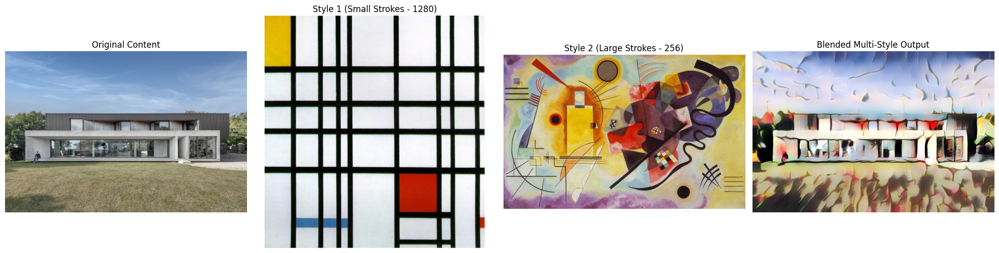

In [10]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Clear cached GPU memory first
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Define paths
content_path = Path('building.jpg')
style1_path = Path('style1_build.jpg')
style2_path = Path('style2_build.jfif')

# Extract and blend inside a no_grad block to prevent OutOfMemory errors
with torch.no_grad():
    # Load and preprocess content image
    content_tensor = load_and_preprocess(content_path, 'content')

    # Apply brushstroke control by loading style images at different target resolutions

    style1_tensor = load_and_preprocess(style1_path, 'style', style_size=1280)
    style2_tensor = load_and_preprocess(style2_path, 'style', style_size=256)

    # Extract deep features using the VGG encoder
    feat_content = encoder(content_tensor)
    feat_style1 = encoder(style1_tensor)
    feat_style2 = encoder(style2_tensor)

    # Compute stylized feature maps with AdaIN at a fixed alpha = 1.0
    stylized_feat1 = adain(feat_content, feat_style1, alpha=1.0)
    stylized_feat2 = adain(feat_content, feat_style2, alpha=1.0)

    # Blend the two stylized feature maps together
    # We will use 50% weight for Style 1 and 50% weight for Style 2
    weights = [0.5, 0.5]
    blended_features = weights[0] * stylized_feat1 + weights[1] * stylized_feat2

    # Decode back into the RGB pixel space
    output_img = decoder(blended_features)
    output_img = torch.clamp(output_img, 0.0, 1.0).squeeze(0).permute(1, 2, 0)

# Plot the input images and the final stylized blended output
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Plot Content
axes[0].imshow(Image.open(content_path))
axes[0].set_title("Original Content")
axes[0].axis("off")

# Plot Style 1
axes[1].imshow(Image.open(style1_path))
axes[1].set_title("Style 1 (Small Strokes - 1280)")
axes[1].axis("off")

# Plot Style 2
axes[2].imshow(Image.open(style2_path))
axes[2].set_title("Style 2 (Large Strokes - 256)")
axes[2].axis("off")

# Plot Blended Result
axes[3].imshow(output_img.cpu().numpy())
axes[3].set_title("Blended Multi-Style Output")
axes[3].axis("off")

plt.tight_layout()
plt.show()

# Clear GPU memory if active
if torch.cuda.is_available():
    torch.cuda.empty_cache()